In [126]:

# Load the German Credit Risk dataset and check its structure.
import pandas as pd
import numpy as np

df = pd.read_csv(r"E:\decision tree\german_credit_data.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())


Dataset shape: (1000, 11)

Column names:
['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk']

First 5 rows:
   Unnamed: 0  Age     Sex  Job Housing Saving accounts Checking account  \
0           0   67    male    2     own             NaN           little   
1           1   22  female    2     own          little         moderate   
2           2   49    male    1     own          little              NaN   
3           3   45    male    2    free          little           little   
4           4   53    male    2    free          little           little   

   Credit amount  Duration              Purpose  Risk  
0           1169         6             radio/TV  good  
1           5951        48             radio/TV   bad  
2           2096        12            education  good  
3           7882        42  furniture/equipment  good  
4           4870        24                  car   bad  


In [127]:

# Prepare the feature and target for splitting-criteria calculations.

sample = df[["Checking account", "Risk"]].dropna().copy()

print("Sample shape:", sample.shape)
print("\nChecking account categories:")
print(sample["Checking account"].value_counts())

print("\nRisk distribution:")
print(sample["Risk"].value_counts())


Sample shape: (606, 2)

Checking account categories:
Checking account
little      274
moderate    269
rich         63
Name: count, dtype: int64

Risk distribution:
Risk
good    352
bad     254
Name: count, dtype: int64


In [128]:

# Calculate Entropy and Information Gain from scratch.

def entropy(labels):
    probabilities = labels.value_counts(normalize=True)
    return -sum(p * np.log2(p) for p in probabilities if p > 0)


def information_gain(data, feature, target):
    parent_entropy = entropy(data[target])
    weighted_child_entropy = 0

    for category in data[feature].unique():
        subset = data[data[feature] == category]
        weight = len(subset) / len(data)

        weighted_child_entropy += weight * entropy(subset[target])

    return parent_entropy - weighted_child_entropy


parent_entropy = entropy(sample["Risk"])
ig = information_gain(sample, "Checking account", "Risk")

print("Parent Entropy:", round(parent_entropy, 4))
print("Information Gain:", round(ig, 4))


Parent Entropy: 0.9811
Information Gain: 0.0212


In [129]:

# Calculate Gini Impurity from scratch.

def gini_impurity(labels):
    probabilities = labels.value_counts(normalize=True)
    return 1 - sum(p ** 2 for p in probabilities)


def gini_split(data, feature, target):
    weighted_child_gini = 0

    for category in data[feature].unique():
        subset = data[data[feature] == category]
        weight = len(subset) / len(data)

        weighted_child_gini += weight * gini_impurity(subset[target])

    return weighted_child_gini


parent_gini = gini_impurity(sample["Risk"])
split_gini = gini_split(sample, "Checking account", "Risk")

print("Parent Gini Impurity:", round(parent_gini, 4))
print("Weighted Gini After Split:", round(split_gini, 4))
print("Gini Reduction:", round(parent_gini - split_gini, 4))


Parent Gini Impurity: 0.4869
Weighted Gini After Split: 0.4732
Gini Reduction: 0.0137


In [130]:

# Manually calculate Entropy and Gini for the rich category.

good = 49
bad = 14
total = good + bad

p_good = good / total
p_bad = bad / total

# Entropy calculation
entropy_manual = -(
    p_good * np.log2(p_good) +
    p_bad * np.log2(p_bad)
)

# Gini calculation
gini_manual = 1 - (p_good ** 2 + p_bad ** 2)

print("Total:", total)
print("P(good):", round(p_good, 4))
print("P(bad):", round(p_bad, 4))
print("Manual Entropy:", round(entropy_manual, 4))
print("Manual Gini:", round(gini_manual, 4))


Total: 63
P(good): 0.7778
P(bad): 0.2222
Manual Entropy: 0.7642
Manual Gini: 0.3457


In [131]:

# Compare the best Entropy and Gini splits for each feature.

features = ["Checking account", "Saving accounts", "Housing", "Sex", "Purpose"]
comparison_results = []

for feature in features:
    data = df[[feature, "Risk"]].dropna().copy()
    results = []

    for category in data[feature].unique():
        temp = data.copy()
        temp["Split"] = np.where(
            temp[feature] == category, "Selected", "Other"
        )

        ig = information_gain(temp, "Split", "Risk")
        gr = gini_impurity(temp["Risk"]) - gini_split(temp, "Split", "Risk")

        results.append({
            "Category": category,
            "Information Gain": ig,
            "Gini Reduction": gr
        })

    scores = pd.DataFrame(results)
    best_ig = scores.loc[scores["Information Gain"].idxmax()]
    best_gini = scores.loc[scores["Gini Reduction"].idxmax()]

    comparison_results.append({
        "Feature": feature,
        "Best Entropy Split": best_ig["Category"],
        "Information Gain": best_ig["Information Gain"],
        "Best Gini Split": best_gini["Category"],
        "Gini Reduction": best_gini["Gini Reduction"],
        "Different Splits": best_ig["Category"] != best_gini["Category"]
    })

results_df = pd.DataFrame(comparison_results)
print(results_df.round(4).to_string(index=False))


         Feature Best Entropy Split  Information Gain Best Gini Split  Gini Reduction  Different Splits
Checking account               rich            0.0143            rich          0.0090             False
 Saving accounts               rich            0.0098          little          0.0057              True
         Housing                own            0.0127             own          0.0076             False
             Sex               male            0.0040            male          0.0024             False
         Purpose           radio/TV            0.0086        radio/TV          0.0048             False


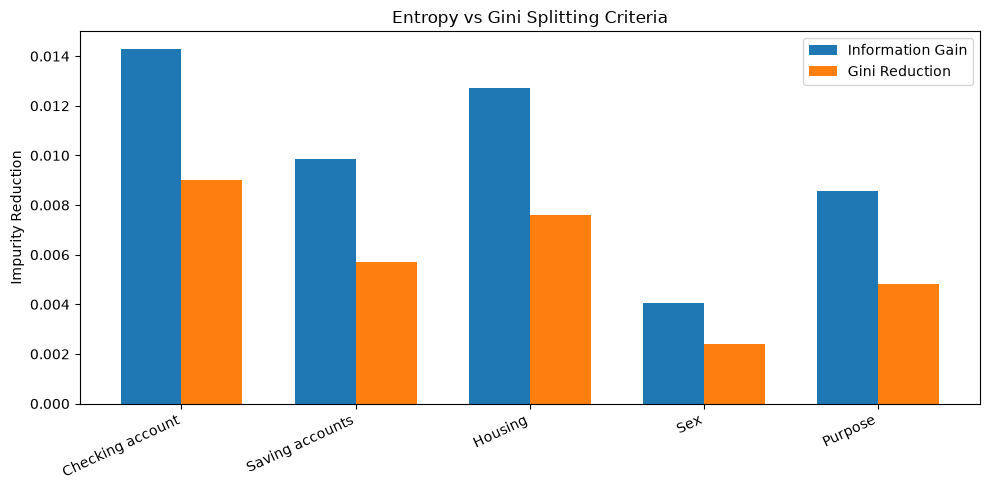

In [132]:
# Visualize Information Gain and Gini Reduction.

import matplotlib.pyplot as plt

plt.close("all")

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(111)

x = np.arange(len(results_df))
width = 0.35

ax.bar(x - width / 2, results_df["Information Gain"].to_numpy(),
       width=width, label="Information Gain")

ax.bar(x + width / 2, results_df["Gini Reduction"].to_numpy(),
       width=width, label="Gini Reduction")

ax.set_xticks(x)
ax.set_xticklabels(results_df["Feature"], rotation=25, ha="right")
ax.set_ylabel("Impurity Reduction")
ax.set_title("Entropy vs Gini Splitting Criteria")
ax.legend()

fig.tight_layout()
plt.show()

In [133]:
# Separate features and target and prepare categorical columns for classification.

df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.dropna()

X = pd.get_dummies(df.drop(columns=["Risk"]), drop_first=True)
y = df["Risk"].map({"good": 0, "bad": 1})

print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (522, 19)

Target distribution:
Risk
0    291
1    231
Name: count, dtype: int64


In [134]:
# Split the dataset into training and testing sets.

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y.values,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 417
Testing samples: 105


In [135]:
# Implement a decision tree from scratch using Gini impurity and recursive splitting.

class DecisionTree:
    def __init__(self, max_depth=3):
        self.max_depth = max_depth
        self.tree = None

    def gini(self, y):
        if len(y) == 0:
            return 0
        probabilities = np.bincount(y) / len(y)
        return 1 - np.sum(probabilities ** 2)

    def best_split(self, X, y):
        best_gain = 0
        best_split = None
        parent_gini = self.gini(y)

        for feature in range(X.shape[1]):
            values = np.unique(X[:, feature])

            for threshold in values[:-1]:
                left = X[:, feature] <= threshold
                right = ~left

                if not left.any() or not right.any():
                    continue

                weighted_gini = (
                    left.sum() * self.gini(y[left]) +
                    right.sum() * self.gini(y[right])
                ) / len(y)

                gain = parent_gini - weighted_gini

                if gain > best_gain:
                    best_gain = gain
                    best_split = (feature, threshold)

        return best_split

    def build_tree(self, X, y, depth):
        majority = np.bincount(y).argmax()

        if depth >= self.max_depth or len(np.unique(y)) == 1:
            return int(majority)

        split = self.best_split(X, y)

        if split is None:
            return int(majority)

        feature, threshold = split
        left = X[:, feature] <= threshold
        right = ~left
        
        # Build the tree recursively using the implemented Gini impurity criterion.
        return {
            "feature": feature,
            "threshold": threshold,
            "left": self.build_tree(X[left], y[left], depth + 1),
            "right": self.build_tree(X[right], y[right], depth + 1)
        }

    def fit(self, X, y):
        self.tree = self.build_tree(X, y, 0)

    def predict_one(self, sample, node):
        if not isinstance(node, dict):
            return node

        if sample[node["feature"]] <= node["threshold"]:
            return self.predict_one(sample, node["left"])

        return self.predict_one(sample, node["right"])

    def predict(self, X):
        return np.array([
            self.predict_one(sample, self.tree) for sample in X
        ])

In [136]:
# Train the decision tree and evaluate its performance on test data.

model = DecisionTree(max_depth=3)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Maximum Depth:", model.max_depth)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Good Risk", "Bad Risk"]))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Maximum Depth: 3
Test Accuracy: 0.6095

Classification Report:
              precision    recall  f1-score   support

   Good Risk       0.62      0.80      0.70        59
    Bad Risk       0.59      0.37      0.45        46

    accuracy                           0.61       105
   macro avg       0.60      0.58      0.57       105
weighted avg       0.60      0.61      0.59       105


Confusion Matrix:
[[47 12]
 [29 17]]


In [137]:
# Trace three test samples through the decision tree step by step.

def trace_prediction(sample, node, feature_names, depth=0):
    if not isinstance(node, dict):
        print("  " * depth + f"Leaf reached: Predicted class = {node}")
        return node

    feature = node["feature"]
    threshold = node["threshold"]
    value = sample[feature]

    print("  " * depth + f"{feature_names[feature]} = {value:.3f} <= {threshold:.3f}?")

    if value <= threshold:
        print("  " * depth + "Yes -> Go left")
        return trace_prediction(sample, node["left"], feature_names, depth + 1)
    else:
        print("  " * depth + "No -> Go right")
        return trace_prediction(sample, node["right"], feature_names, depth + 1)


for i in range(3):
    print(f"\nSample {i + 1}")
    prediction = trace_prediction(
        X_test[i], model.tree, X.columns.tolist()
    )
    actual = y_test[i]

    print("Predicted Risk:", "Good" if prediction == 0 else "Bad")
    print("Actual Risk:   ", "Good" if actual == 0 else "Bad")


Sample 1
Duration = 18.000 <= 42.000?
Yes -> Go left
  Duration = 18.000 <= 16.000?
  No -> Go right
    Credit amount = 3612.000 <= 2319.000?
    No -> Go right
      Leaf reached: Predicted class = 0
Predicted Risk: Good
Actual Risk:    Good

Sample 2
Duration = 18.000 <= 42.000?
Yes -> Go left
  Duration = 18.000 <= 16.000?
  No -> Go right
    Credit amount = 1961.000 <= 2319.000?
    Yes -> Go left
      Leaf reached: Predicted class = 1
Predicted Risk: Bad
Actual Risk:    Good

Sample 3
Duration = 18.000 <= 42.000?
Yes -> Go left
  Duration = 18.000 <= 16.000?
  No -> Go right
    Credit amount = 2864.000 <= 2319.000?
    No -> Go right
      Leaf reached: Predicted class = 0
Predicted Risk: Good
Actual Risk:    Bad


In [138]:

# Train Decision Trees with different maximum depths.

from sklearn.tree import DecisionTreeClassifier

depths = [2, 4, 6, 10, None]
models = {}

for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    models[depth] = tree

    print(f"max_depth={depth}: Tree trained")


max_depth=2: Tree trained
max_depth=4: Tree trained
max_depth=6: Tree trained
max_depth=10: Tree trained
max_depth=None: Tree trained


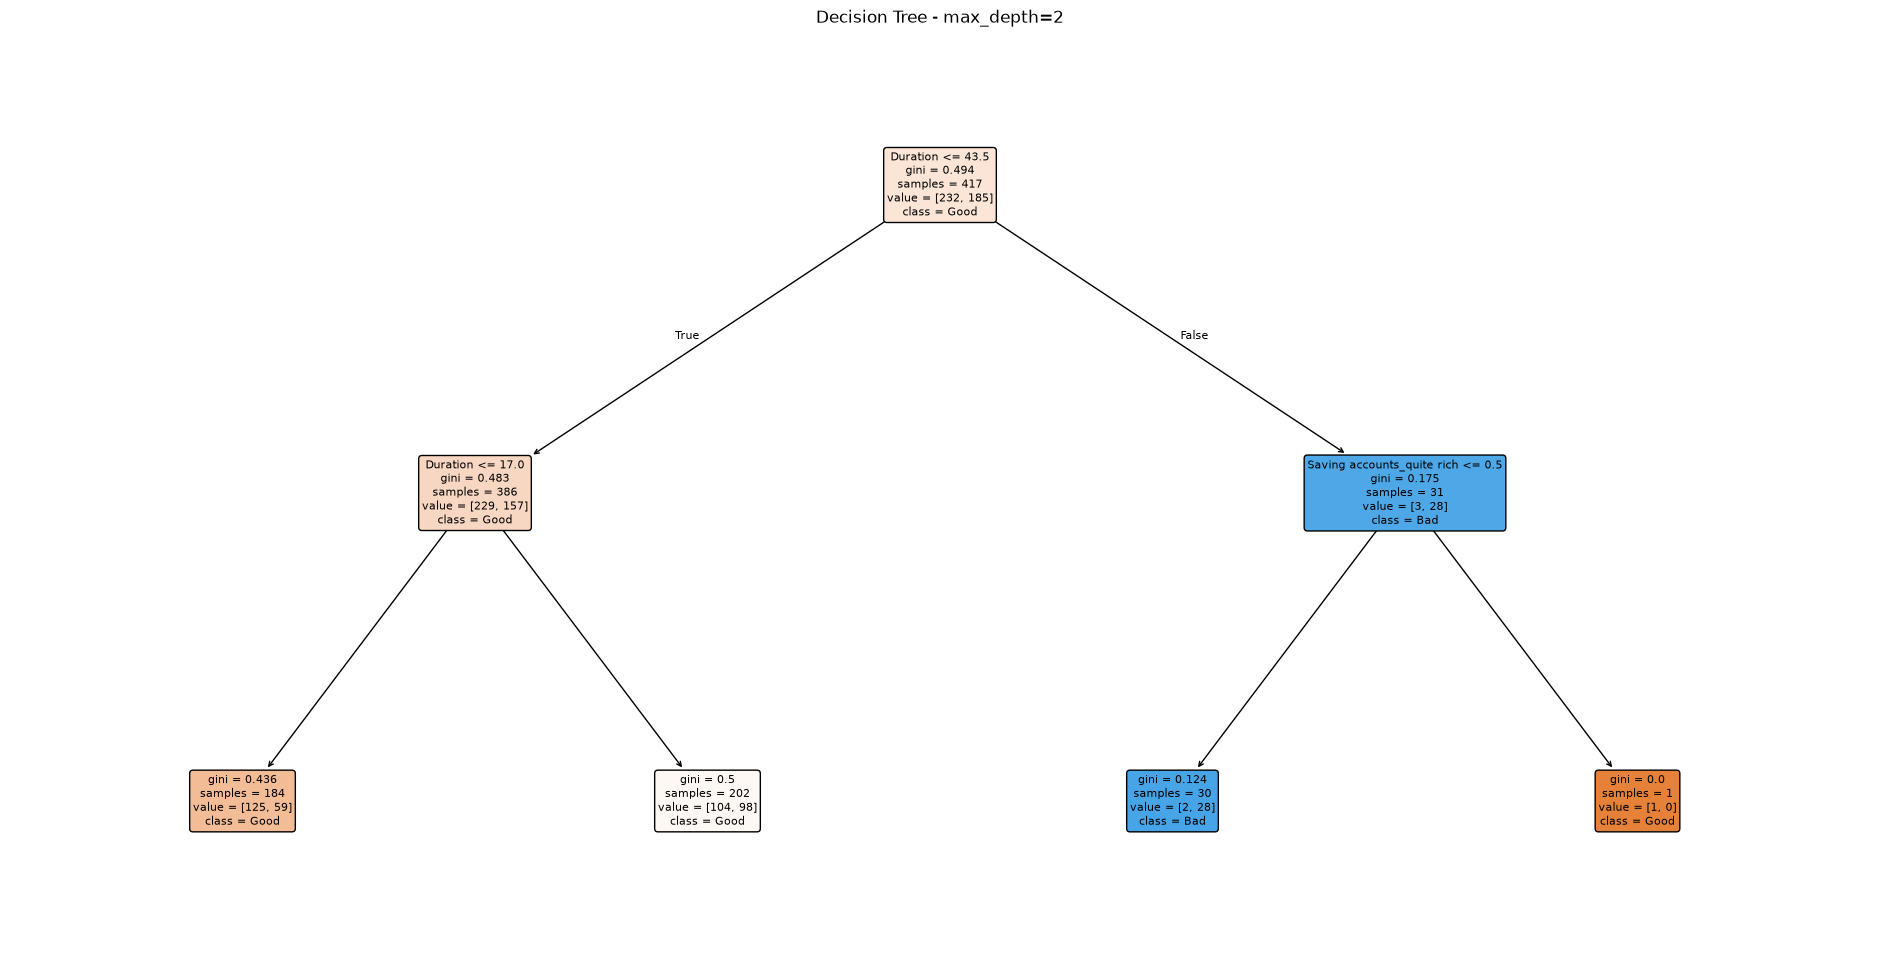

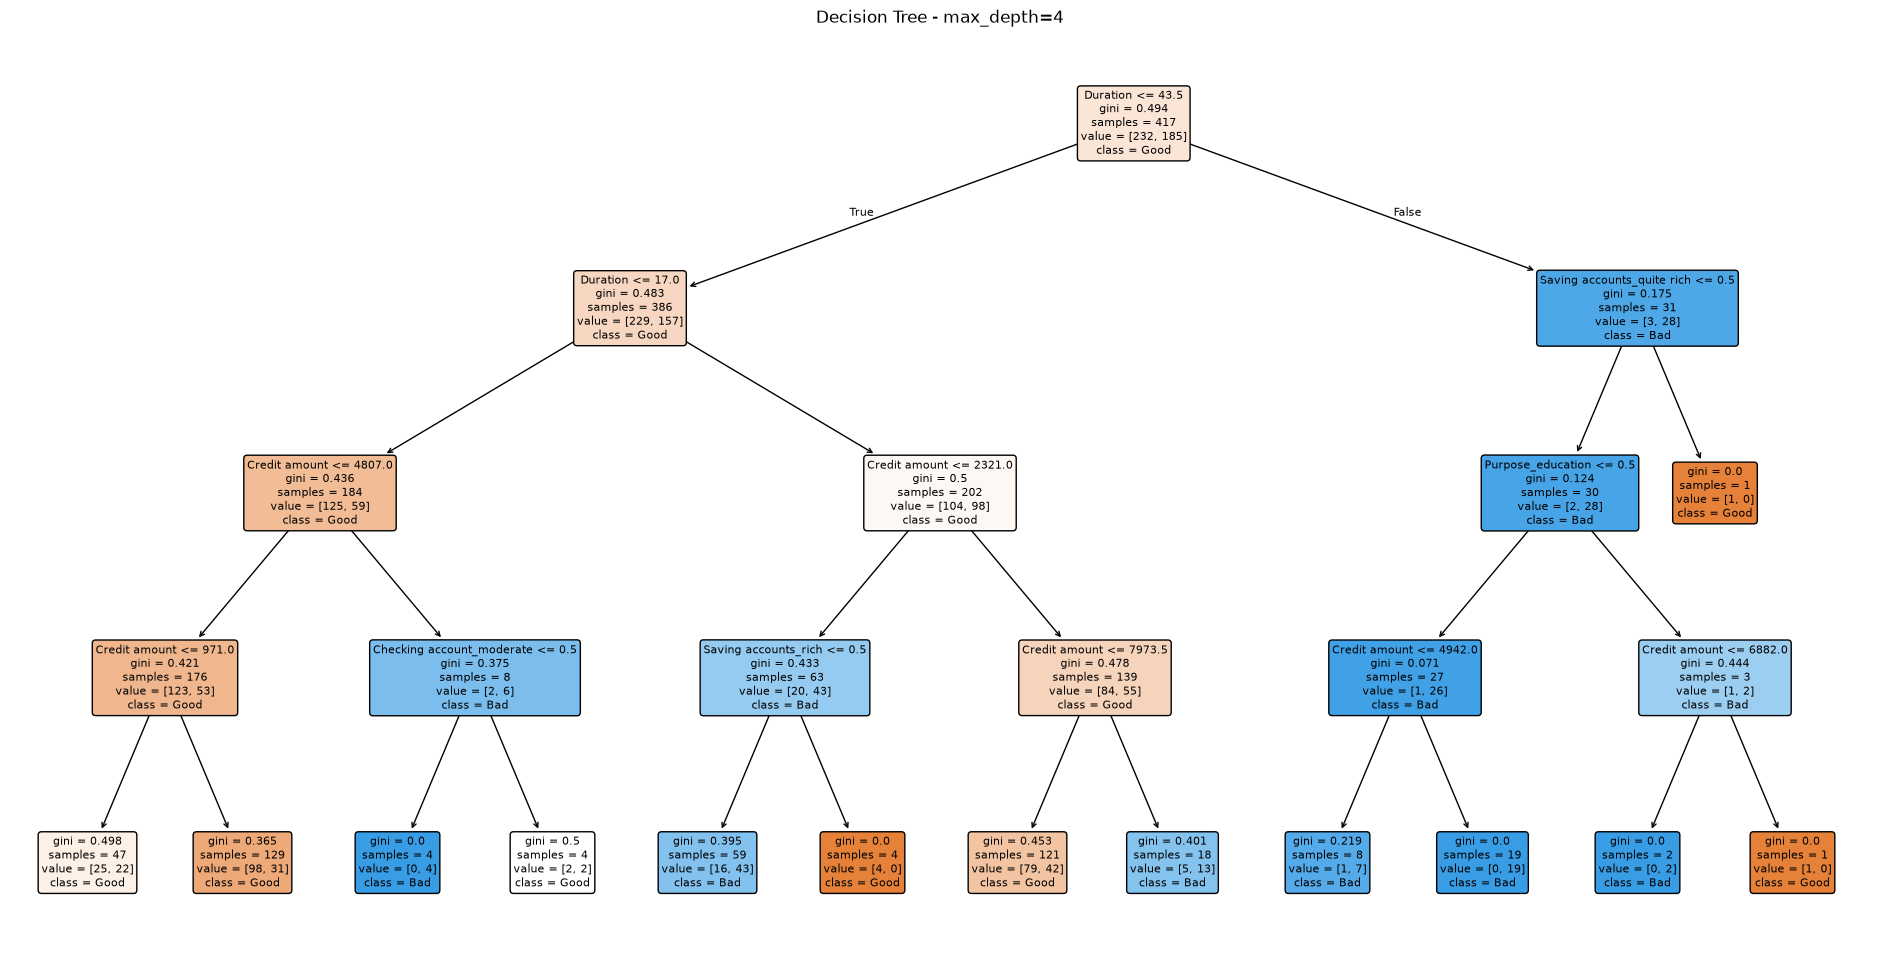

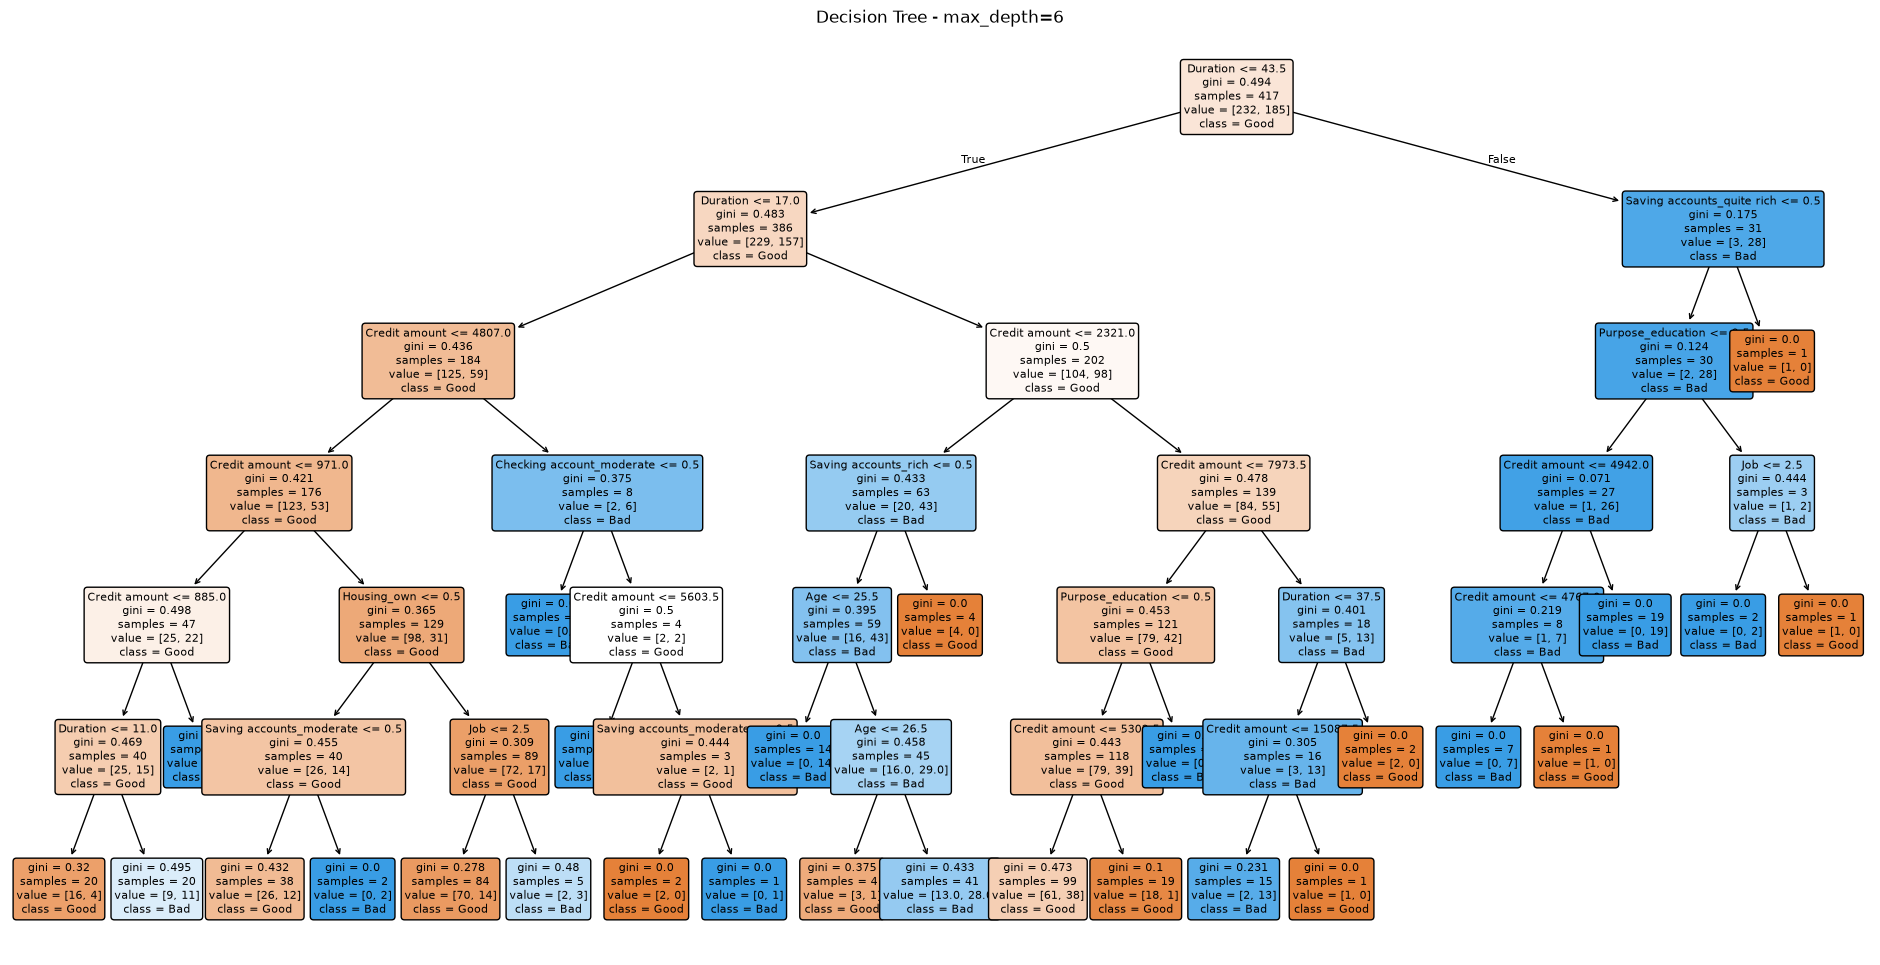

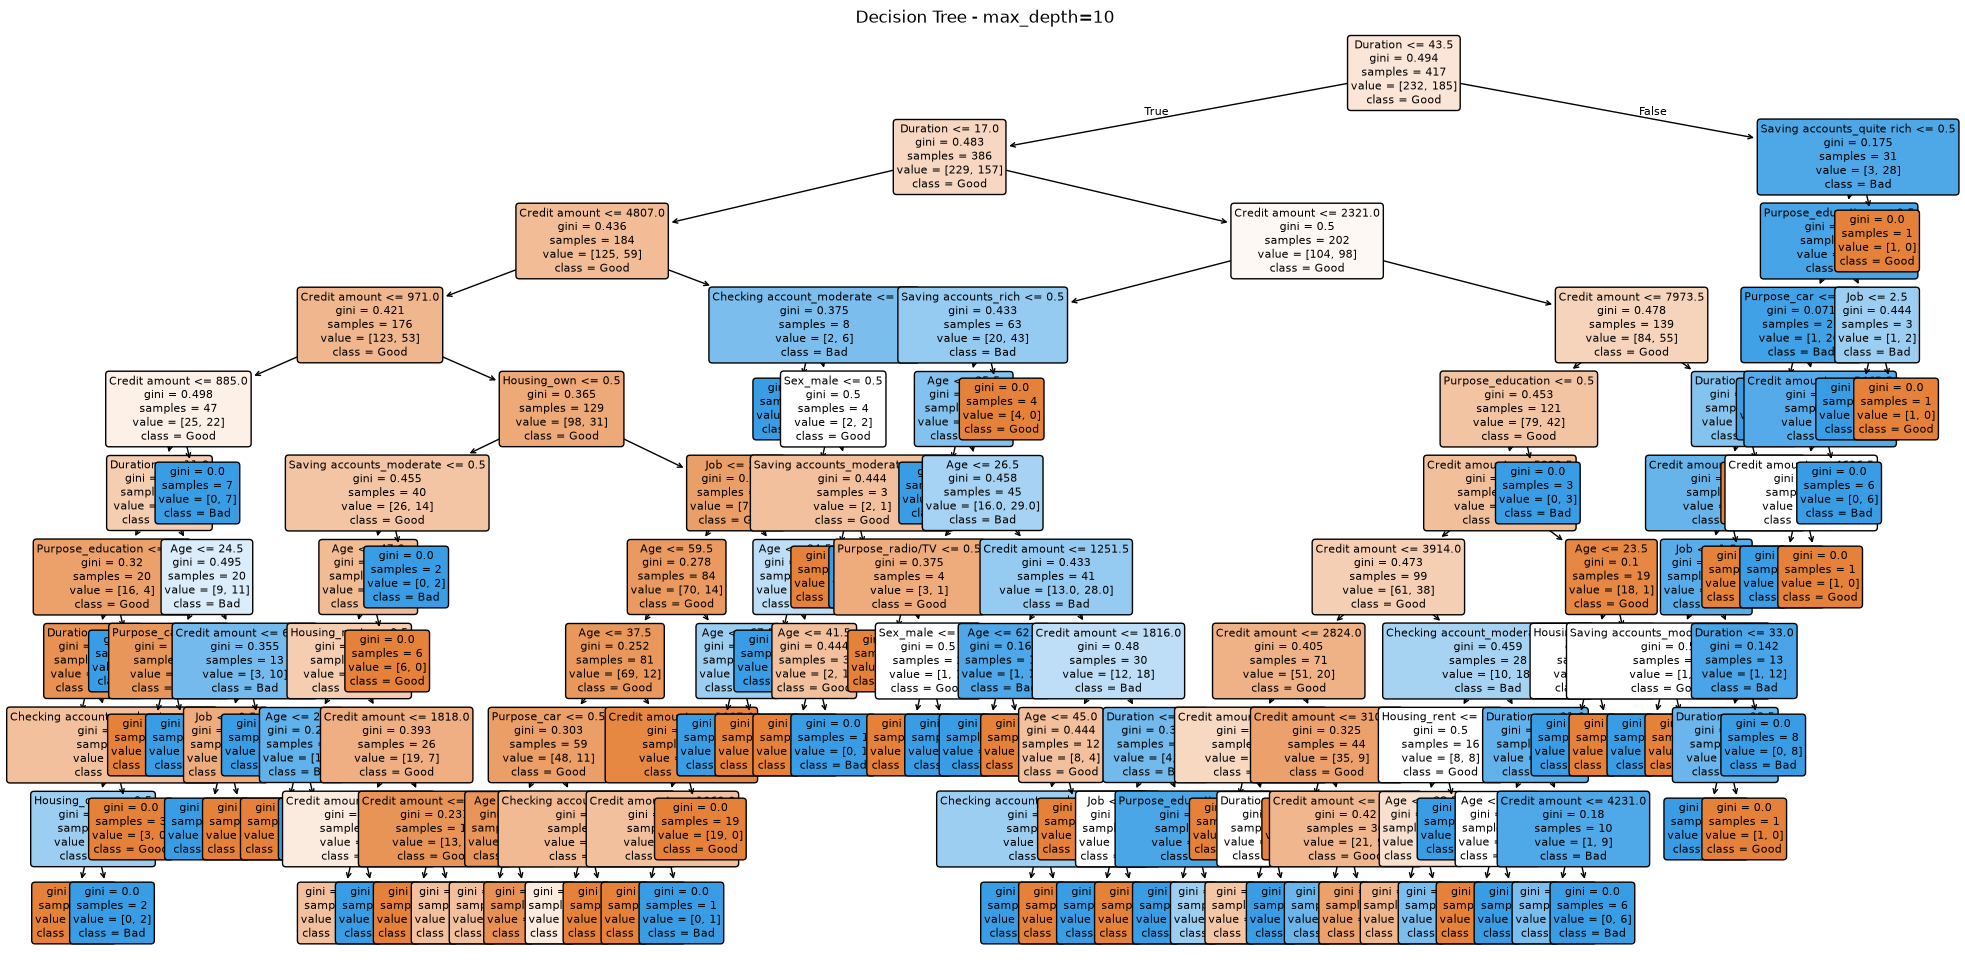

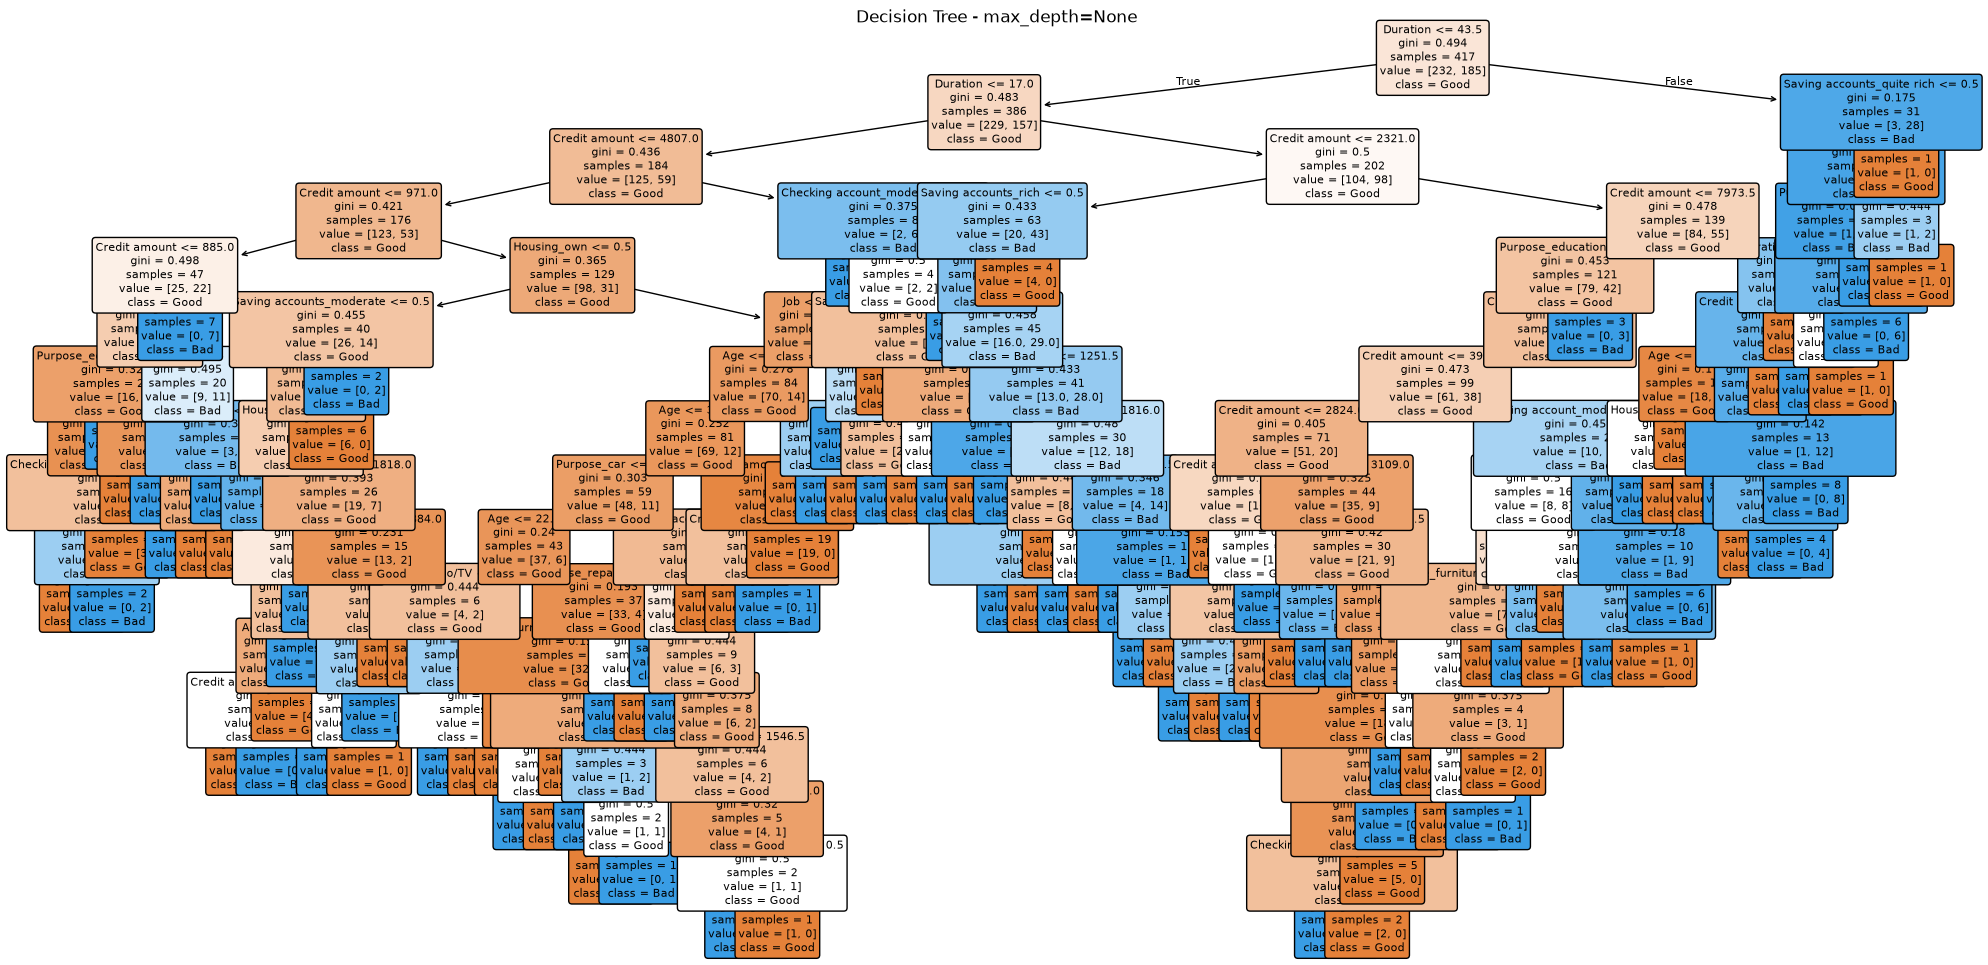

In [139]:

# Visualize each trained Decision Tree using plot_tree.

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

for depth, tree in models.items():
    plt.figure(figsize=(24, 12))

    plot_tree(
        tree,
        feature_names=X.columns.tolist(),
        class_names=["Good", "Bad"],
        filled=True,
        rounded=True,
        fontsize=8
    )

    plt.title(f"Decision Tree - max_depth={depth}")
    plt.show()


In [140]:

# Identify the root split for each trained Decision Tree.

for depth, tree in models.items():
    root_feature_index = tree.tree_.feature[0]
    root_threshold = tree.tree_.threshold[0]
    root_feature = X.columns[root_feature_index]

    print(f"\nmax_depth = {depth}")
    print(f"Root feature: {root_feature}")
    print(f"Split condition: {root_feature} <= {root_threshold:.4f}")
    print(f"Feature importance: {tree.feature_importances_[root_feature_index]:.4f}")



max_depth = 2
Root feature: Duration
Split condition: Duration <= 43.5000
Feature importance: 0.9199

max_depth = 4
Root feature: Duration
Split condition: Duration <= 43.5000
Feature importance: 0.4189

max_depth = 6
Root feature: Duration
Split condition: Duration <= 43.5000
Feature importance: 0.3180

max_depth = 10
Root feature: Duration
Split condition: Duration <= 43.5000
Feature importance: 0.2028

max_depth = None
Root feature: Duration
Split condition: Duration <= 43.5000
Feature importance: 0.1739


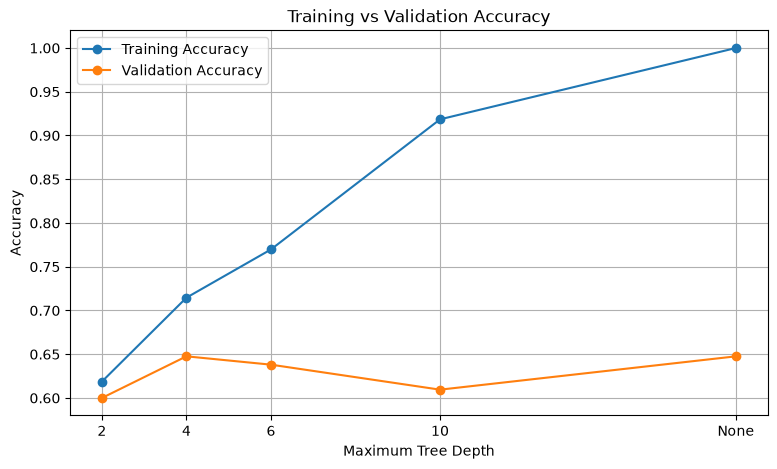

In [141]:
# Compare training and validation accuracy across different tree depths.

import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

depths = [2, 4, 6, 10, None]

train_accuracies = []
val_accuracies = []

for depth in depths:
    tree = models[depth]

    train_pred = tree.predict(X_train)
    val_pred = tree.predict(X_test)

    train_accuracies.append(accuracy_score(y_train, train_pred))
    val_accuracies.append(accuracy_score(y_test, val_pred))

plt.figure(figsize=(9, 5))

plt.plot(depths[:-1] + [17], train_accuracies, marker="o",
         label="Training Accuracy")
plt.plot(depths[:-1] + [17], val_accuracies, marker="o",
         label="Validation Accuracy")

plt.xticks([2, 4, 6, 10, 17], ["2", "4", "6", "10", "None"])
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [142]:
# Identify where validation accuracy first decreases as tree depth increases.

for i in range(1, len(depths)):
    if val_accuracies[i] < val_accuracies[i - 1]:
        print("Overfitting starts to appear at max_depth =", depths[i])
        break
else:
    print("No decrease in validation accuracy detected.")

Overfitting starts to appear at max_depth = 6


In [143]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

for depth in [2, 4, 6, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    print(
        f"Depth: {str(depth):4} | "
        f"Train: {train_acc:.2%} | "
        f"Test: {test_acc:.2%}"
    )

Depth: 2    | Train: 61.87% | Test: 60.00%
Depth: 4    | Train: 71.46% | Test: 64.76%
Depth: 6    | Train: 76.98% | Test: 63.81%
Depth: 10   | Train: 91.85% | Test: 60.95%
Depth: None | Train: 100.00% | Test: 64.76%


In [144]:
# Compare the unpruned tree's performance on training and unseen data.

from sklearn.metrics import accuracy_score

unpruned_tree = models[None]

train_pred = unpruned_tree.predict(X_train)
val_pred = unpruned_tree.predict(X_test)

print("Training Accuracy:", f"{accuracy_score(y_train, train_pred):.2%}")
print("Validation Accuracy:", f"{accuracy_score(y_test, val_pred):.2%}")
print("Training Errors:", (y_train != train_pred).sum())
print("Validation Errors:", (y_test != val_pred).sum())
print("Number of Leaves:", unpruned_tree.get_n_leaves())
print("Tree Depth:", unpruned_tree.get_depth())

Training Accuracy: 100.00%
Validation Accuracy: 64.76%
Training Errors: 0
Validation Errors: 37
Number of Leaves: 121
Tree Depth: 16


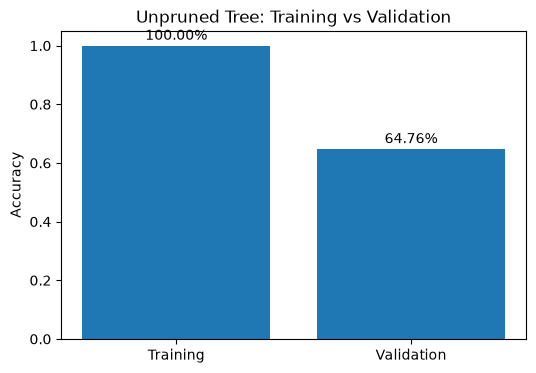

Training errors: 0
Validation errors: 37
Tree depth: 16
Number of leaves: 121


In [145]:
# Compare the unpruned tree's training and validation performance.

from sklearn.metrics import accuracy_score

unpruned_tree = models[None]

train_pred = unpruned_tree.predict(X_train)
val_pred = unpruned_tree.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_test, val_pred)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Training", "Validation"],
    [train_acc, val_acc]
)
plt.ylabel("Accuracy")
plt.title("Unpruned Tree: Training vs Validation")
plt.ylim(0, 1.05)

for i, value in enumerate([train_acc, val_acc]):
    plt.text(i, value + 0.02, f"{value:.2%}", ha="center")

plt.show()

print("Training errors:", (y_train != train_pred).sum())
print("Validation errors:", (y_test != val_pred).sum())
print("Tree depth:", unpruned_tree.get_depth())
print("Number of leaves:", unpruned_tree.get_n_leaves())

In [146]:
param_grid = {
    'max_depth': [3, 5, 7, 10],
    'min_samples_split': [2, 5, 10, 20]
}
dt = DecisionTreeClassifier(random_state=42)

In [147]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [148]:
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_split': 20}
Best Cross-Validation Accuracy: 0.6306942053930006


In [149]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

val_accuracy = accuracy_score(y_test, y_pred)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search.best_score_, 4))
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Accuracy (%):", round(val_accuracy * 100, 2), "%")

Best Parameters: {'max_depth': 10, 'min_samples_split': 20}
Best Cross-Validation Accuracy: 0.6307
Validation Accuracy: 0.6
Validation Accuracy (%): 60.0 %


In [ ]:
from sklearn.tree import export_text

feature_names = X.columns.tolist()

tree_rules = export_text(
    best_model,
    feature_names=feature_names,
    max_depth=5
)

print(tree_rules)

|--- Duration <= 43.50
|   |--- Duration <= 17.00
|   |   |--- Credit amount <= 4807.00
|   |   |   |--- Credit amount <= 971.00
|   |   |   |   |--- Credit amount <= 885.00
|   |   |   |   |   |--- Duration <= 11.00
|   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |   |--- Duration >  11.00
|   |   |   |   |   |   |--- truncated branch of depth 2
|   |   |   |   |--- Credit amount >  885.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- Credit amount >  971.00
|   |   |   |   |--- Housing_own <= 0.50
|   |   |   |   |   |--- Saving accounts_moderate <= 0.50
|   |   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |   |--- Saving accounts_moderate >  0.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- Housing_own >  0.50
|   |   |   |   |   |--- Job <= 2.50
|   |   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |   |--- Job >  2.50
|   |   |   |   |   |   |--- class: 1
|   |   |--- Credit amount >  4807.00
|   | 

In [151]:
import numpy as np

tree = best_model.tree_
rules = []

def extract_rules(node, conditions):
    if tree.children_left[node] == tree.children_right[node]:
        predicted_class = best_model.classes_[np.argmax(tree.value[node][0])]
        samples = tree.n_node_samples[node]

        rules.append({
            "Conditions": " AND ".join(conditions),
            "Predicted Class": predicted_class,
            "Samples": samples
        })
        return

    feature = feature_names[tree.feature[node]]
    threshold = tree.threshold[node]

    extract_rules(
        tree.children_left[node],
        conditions + [f"{feature} <= {threshold:.2f}"]
    )

    extract_rules(
        tree.children_right[node],
        conditions + [f"{feature} > {threshold:.2f}"]
    )

extract_rules(0, [])

top_5_rules = sorted(
    rules,
    key=lambda rule: rule["Samples"],
    reverse=True
)[:5]

top_5_rules_df = pd.DataFrame(top_5_rules)
display(top_5_rules_df)

,Conditions,Predicted Class,Samples
0,Duration <= 43.50 AND Duration <= 17.00 AND Credit amount <= 4807.00 AND Credit amount > 971.00 AND Housing_own > 0.50 AND Job <= 2.50 AND Age <= 59.50 AND Age <= 37.50 AND Purpose_car <= 0.50 AND Age > 22.50,0,37
1,Duration <= 43.50 AND Duration > 17.00 AND Credit amount > 2321.00 AND Credit amount <= 7973.50 AND Purpose_education <= 0.50 AND Credit amount <= 5302.50 AND Credit amount <= 3914.00 AND Credit amount > 2824.00 AND Credit amount > 3109.00 AND Credit amount > 3201.50,0,25
2,Duration <= 43.50 AND Duration <= 17.00 AND Credit amount <= 4807.00 AND Credit amount > 971.00 AND Housing_own > 0.50 AND Job <= 2.50 AND Age <= 59.50 AND Age > 37.50 AND Credit amount > 1087.00,0,19
3,Duration <= 43.50 AND Duration > 17.00 AND Credit amount > 2321.00 AND Credit amount <= 7973.50 AND Purpose_education <= 0.50 AND Credit amount > 5302.50,0,19
4,Duration > 43.50 AND Saving accounts_quite rich <= 0.50 AND Purpose_education <= 0.50 AND Credit amount > 4942.00,1,19


In [153]:
def convert_rule_to_english(rule):
    conditions = rule["Conditions"].split(" AND ")
    readable_conditions = []

    for condition in conditions:
        if "<=" in condition:
            feature, value = condition.split(" <= ")
            readable_conditions.append(f"{feature} is less than or equal to {value}")
        elif ">" in condition:
            feature, value = condition.split(" > ")
            readable_conditions.append(f"{feature} is greater than {value}")

    return (
        "If " + ", and ".join(readable_conditions)
        + f", then predict class {rule['Predicted Class']} "
        + f"({rule['Samples']} training samples)."
    )


for i, rule in enumerate(top_5_rules, start=1):
    print(f"Rule {i}:")
    print(convert_rule_to_english(rule))
    print() 

Rule 1:
If Duration is less than or equal to 43.50, and Duration is less than or equal to 17.00, and Credit amount is less than or equal to 4807.00, and Credit amount is greater than 971.00, and Housing_own is greater than 0.50, and Job is less than or equal to 2.50, and Age is less than or equal to 59.50, and Age is less than or equal to 37.50, and Purpose_car is less than or equal to 0.50, and Age is greater than 22.50, then predict class 0 (37 training samples).

Rule 2:
If Duration is less than or equal to 43.50, and Duration is greater than 17.00, and Credit amount is greater than 2321.00, and Credit amount is less than or equal to 7973.50, and Purpose_education is less than or equal to 0.50, and Credit amount is less than or equal to 5302.50, and Credit amount is less than or equal to 3914.00, and Credit amount is greater than 2824.00, and Credit amount is greater than 3109.00, and Credit amount is greater than 3201.50, then predict class 0 (25 training samples).

Rule 3:
If Dura

In [ ]:
from sklearn.tree import _tree
import pandas as pd
import numpy as np

feature_names = X.columns.tolist()
tree = best_model.tree_
risk_segments = []

bad_class = 1  # Confirm that class 1 represents "bad" credit

def extract_risk_segments(node, conditions):
    if tree.children_left[node] == _tree.TREE_LEAF:
        values = tree.value[node][0]
        total = values.sum()
        bad_count = values[list(best_model.classes_).index(bad_class)]
        bad_rate = bad_count / total if total else 0

        risk_segments.append({
            "Customer Segment": " AND ".join(conditions) if conditions else "All customers",
            "Samples": int(tree.n_node_samples[node]),
            "Bad Credit Rate (%)": round(bad_rate * 100, 2),
            "Predicted Class": best_model.classes_[np.argmax(values)]
        })
        return

    feature = feature_names[tree.feature[node]]
    threshold = tree.threshold[node]

    extract_risk_segments(
        tree.children_left[node],
        conditions + [f"{feature} <= {threshold:.2f}"]
    )
    extract_risk_segments(
        tree.children_right[node],
        conditions + [f"{feature} > {threshold:.2f}"]
    )

extract_risk_segments(0, [])

risk_df = pd.DataFrame(risk_segments)
highest_risk = risk_df.sort_values(
    by="Bad Credit Rate (%)",
    ascending=False
).head(5)

display(highest_risk)

,Customer Segment,Samples,Bad Credit Rate (%),Predicted Class
1,Duration <= 43.50 AND Duration <= 17.00 AND Credit amount <= 4807.00 AND Credit amount <= 971.00 AND Credit amount <= 885.00 AND Duration <= 11.00 AND Purpose_education > 0.50,2,100.0,1
4,Duration <= 43.50 AND Duration <= 17.00 AND Credit amount <= 4807.00 AND Credit amount <= 971.00 AND Credit amount > 885.00,7,100.0,1
36,Duration > 43.50 AND Saving accounts_quite rich <= 0.50 AND Purpose_education <= 0.50 AND Credit amount > 4942.00,19,100.0,1
26,Duration <= 43.50 AND Duration > 17.00 AND Credit amount > 2321.00 AND Credit amount <= 7973.50 AND Purpose_education <= 0.50 AND Credit amount <= 5302.50 AND Credit amount <= 3914.00 AND Credit amount <= 2824.00 AND Credit amount > 2356.00 AND Duration > 33.00,5,100.0,1
33,Duration <= 43.50 AND Duration > 17.00 AND Credit amount > 2321.00 AND Credit amount <= 7973.50 AND Purpose_education > 0.50,3,100.0,1
